In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_DIR = Path("/internmo internship projects/project 2")
OUTPUT_DIR = Path("phase3_outputs")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Data folder:", DATA_DIR.resolve())
print("Output folder:", OUTPUT_DIR.resolve())


Data folder: D:\internmo internship projects\project 2
Output folder: D:\internmo internship projects\project 2\phase3_outputs


In [3]:
required_files = [
    "customers.csv",
    "subscriptions.csv",
    "plans.csv",
    "billing.csv",
    "support_tickets.csv",
    "contracts.csv",
    "retention_campaigns.csv"
]

data = {}

for filename in required_files:
    filepath = DATA_DIR / filename

    if filepath.exists():
        data[filename.replace(".csv", "")] = pd.read_csv(filepath)
        print(f"Loaded: {filename} | Rows: {len(data[filename.replace('.csv', '')]):,}")
    else:
        print(f"WARNING: File not found — {filename}")

customers = data.get("customers", pd.DataFrame())
subscriptions = data.get("subscriptions", pd.DataFrame())
plans = data.get("plans", pd.DataFrame())
billing = data.get("billing", pd.DataFrame())
support_tickets = data.get("support_tickets", pd.DataFrame())
contracts = data.get("contracts", pd.DataFrame())
retention_campaigns = data.get("retention_campaigns", pd.DataFrame())

Loaded: customers.csv | Rows: 19,076
Loaded: subscriptions.csv | Rows: 20,523
Loaded: plans.csv | Rows: 25
Loaded: billing.csv | Rows: 115,313
Loaded: support_tickets.csv | Rows: 31,490
Loaded: contracts.csv | Rows: 10,607
Loaded: retention_campaigns.csv | Rows: 6,475


In [4]:
for table_name, df in data.items():
    print(f"\n--- {table_name.upper()} ---")
    print(df.columns.tolist())


--- CUSTOMERS ---
['customer_id', 'first_name', 'last_name', 'gender', 'date_of_birth', 'age', 'email', 'phone_number', 'address', 'city_id', 'city_name', 'state_id', 'pin_code', 'city_tier', 'region_id', 'occupation', 'annual_income_inr', 'customer_segment', 'product_line', 'plan_id', 'acquisition_channel', 'acquisition_date', 'tenure_months', 'customer_status', 'churn_date']

--- SUBSCRIPTIONS ---
['subscription_id', 'customer_id', 'plan_id', 'start_date', 'end_date', 'billing_cycle', 'monthly_charge_inr', 'subscription_status']

--- PLANS ---
['plan_id', 'plan_name', 'product_line', 'billing_cycle', 'monthly_charge', 'data_quota_gb', 'voice_minutes', 'sms_count', 'segment', 'is_active']

--- BILLING ---
['invoice_id', 'customer_id', 'billing_date', 'billing_period_month', 'base_amount_inr', 'gst_amount_inr', 'total_amount_inr', 'due_date', 'payment_status']

--- SUPPORT_TICKETS ---
['ticket_id', 'customer_id', 'created_date', 'category', 'priority', 'channel', 'status', 'first_cont

In [5]:
def find_col(df, candidates):
    """Candidate list mein se pehla available column return karta hai."""
    if df is None or df.empty:
        return None

    lookup = {col.lower().strip(): col for col in df.columns}

    for candidate in candidates:
        if candidate.lower().strip() in lookup:
            return lookup[candidate.lower().strip()]

    return None


def numeric_series(df, column):
    """Column ko numeric format mein convert karta hai."""
    if df is None or column is None or column not in df.columns:
        return pd.Series(dtype="float64")

    return pd.to_numeric(df[column], errors="coerce")


def percentage(numerator, denominator):
    if denominator is None or denominator == 0 or pd.isna(denominator):
        return np.nan
    return numerator / denominator * 100


kpi_results = []

def add_kpi(name, value, unit, note):
    kpi_results.append({
        "KPI": name,
        "Value": value,
        "Unit": unit,
        "Notes": note
    })

In [6]:
customer_id_col = find_col(customers, ["customer_id"])
status_col = find_col(customers, ["customer_status", "churn_status", "status"])
churn_date_col = find_col(customers, ["churn_date"])
acquisition_date_col = find_col(
    customers,
    ["acquisition_date", "signup_date", "join_date", "customer_since"]
)
tenure_col = find_col(customers, ["tenure_months", "tenure"])

if customers.empty or customer_id_col is None:
    raise ValueError("customers.csv missing hai ya customer_id column nahi mila.")

customers_kpi = customers.copy()

if status_col:
    customers_kpi["_status"] = (
        customers_kpi[status_col].astype(str).str.strip().str.lower()
    )
    customers_kpi["_churned"] = customers_kpi["_status"].isin(
        ["churned", "churn", "terminated", "inactive"]
    )
else:
    customers_kpi["_churned"] = False
    print("WARNING: Customer status column nahi mila.")

customers_kpi["_churn_date"] = (
    pd.to_datetime(customers_kpi[churn_date_col], errors="coerce", dayfirst=True)
    if churn_date_col else pd.NaT
)

customers_kpi["_acquisition_date"] = (
    pd.to_datetime(
        customers_kpi[acquisition_date_col],
        errors="coerce",
        dayfirst=True
    )
    if acquisition_date_col else pd.NaT
)

print("Total unique customers:", customers_kpi[customer_id_col].nunique())
print("Churned customers:", int(customers_kpi["_churned"].sum()))
print("Acquisition date column:", acquisition_date_col)
print("Churn date column:", churn_date_col)

Total unique customers: 19000
Churned customers: 3516
Acquisition date column: acquisition_date
Churn date column: churn_date


In [7]:
if acquisition_date_col and churn_date_col:
    valid_dates = customers_kpi["_acquisition_date"].dropna()

    if not valid_dates.empty:
        # Dataset mein available latest month select karo
        analysis_month = customers_kpi["_churn_date"].max()

        if pd.isna(analysis_month):
            analysis_month = customers_kpi["_acquisition_date"].max()

        month_start = analysis_month.to_period("M").start_time
        month_end = analysis_month.to_period("M").end_time

        existed_at_start = (
            customers_kpi["_acquisition_date"].notna()
            & (customers_kpi["_acquisition_date"] < month_start)
            & (
                customers_kpi["_churn_date"].isna()
                | (customers_kpi["_churn_date"] >= month_start)
            )
        )

        churned_during_month = (
            customers_kpi["_churn_date"].between(
                month_start, month_end, inclusive="both"
            )
        )

        start_count = int(existed_at_start.sum())
        lost_count = int((existed_at_start & churned_during_month).sum())

        monthly_churn_rate = percentage(lost_count, start_count)

        add_kpi(
            "Customer Churn Rate",
            monthly_churn_rate,
            "%",
            f"Estimated for {month_start:%Y-%m}; {lost_count} lost / {start_count} at start"
        )

        print("Analysis month:", month_start.strftime("%Y-%m"))
        print("Customers at start:", start_count)
        print("Customers lost during month:", lost_count)
        print(f"Monthly churn rate: {monthly_churn_rate:.2f}%"
              if pd.notna(monthly_churn_rate) else "Monthly churn rate unavailable")
    else:
        print("Monthly churn calculate nahi hua: valid acquisition dates nahi hain.")
else:
    total_customers = customers_kpi[customer_id_col].nunique()
    churned_customers = customers_kpi.loc[
        customers_kpi["_churned"], customer_id_col
    ].nunique()

    overall_churn = percentage(churned_customers, total_customers)

    add_kpi(
        "Overall/Lifetime Churn Proportion",
        overall_churn,
        "%",
        "Monthly churn nahi hai; start-of-month customer count available nahi."
    )

    print(f"Overall/lifetime churn proportion: {overall_churn:.2f}%")

Analysis month: 2026-03
Customers at start: 15439
Customers lost during month: 192
Monthly churn rate: 1.24%


In [8]:
if (
    acquisition_date_col
    and churn_date_col
    and "month_start" in globals()
    and "month_end" in globals()
):
    new_customers = int(
        customers_kpi["_acquisition_date"].between(
            month_start, month_end, inclusive="both"
        ).sum()
    )

    active_at_end = (
        customers_kpi["_acquisition_date"].notna()
        & (customers_kpi["_acquisition_date"] <= month_end)
        & (
            customers_kpi["_churn_date"].isna()
            | (customers_kpi["_churn_date"] > month_end)
        )
    )

    end_count = int(active_at_end.sum())

    retention_rate = percentage(
        end_count - new_customers,
        start_count
    )

    add_kpi(
        "Customer Retention Rate",
        retention_rate,
        "%",
        f"({end_count} end - {new_customers} new) / {start_count} start"
    )

    print("New customers:", new_customers)
    print("Customers active at end:", end_count)
    print(f"Retention rate: {retention_rate:.2f}%"
          if pd.notna(retention_rate) else "Retention rate unavailable")
else:
    print("Retention rate skip: reliable acquisition/churn dates nahi mile.")

New customers: 3
Customers active at end: 15248
Retention rate: 98.74%


In [9]:
sub_customer_col = find_col(subscriptions, ["customer_id"])
sub_status_col = find_col(subscriptions, ["subscription_status", "status"])
charge_col = find_col(
    subscriptions,
    ["monthly_charge_inr", "monthly_charge", "recurring_charge_inr"]
)

if not subscriptions.empty and charge_col:
    subscriptions_kpi = subscriptions.copy()
    subscriptions_kpi["_monthly_charge"] = pd.to_numeric(
        subscriptions_kpi[charge_col], errors="coerce"
    )

    if sub_status_col:
        subscriptions_kpi["_sub_status"] = (
            subscriptions_kpi[sub_status_col].astype(str).str.strip().str.lower()
        )
        active_subscriptions = subscriptions_kpi[
            subscriptions_kpi["_sub_status"] == "active"
        ].copy()
    else:
        active_subscriptions = subscriptions_kpi.copy()
        print("WARNING: Subscription status missing; all subscriptions included.")

    mrr = active_subscriptions["_monthly_charge"].sum(min_count=1)

    if sub_customer_col:
        active_subscriber_count = active_subscriptions[sub_customer_col].nunique()
    else:
        active_subscriber_count = len(active_subscriptions)

    print("Active subscriptions:", len(active_subscriptions))
    print("Active unique subscribers:", active_subscriber_count)
    print(f"MRR: ₹{mrr:,.2f}" if pd.notna(mrr) else "MRR unavailable")

    add_kpi(
        "Monthly Recurring Revenue (MRR)",
        mrr,
        "INR",
        "Sum of monthly charges for active subscriptions"
    )
else:
    active_subscriptions = pd.DataFrame()
    active_subscriber_count = 0
    mrr = np.nan
    print("MRR calculate nahi hua: subscriptions ya charge column missing hai.")

Active subscriptions: 16930
Active unique subscribers: 15674
MRR: ₹14,920,323.00


In [10]:
if active_subscriber_count > 0 and pd.notna(mrr):
    arpu = mrr / active_subscriber_count

    add_kpi(
        "ARPU",
        arpu,
        "INR per subscriber/month",
        "Estimated as active-subscription MRR / current active subscribers"
    )

    print(f"Estimated ARPU: ₹{arpu:,.2f} per subscriber/month")
else:
    arpu = np.nan
    print("ARPU unavailable: MRR ya active subscriber count missing hai.")

Estimated ARPU: ₹951.92 per subscriber/month


In [11]:
GROSS_MARGIN_PCT = 30  # Assumption: 30%; actual figure mile toh update karo

# CLV formula mein churn rate decimal form mein chahiye.
# Monthly churn rate available ho tabhi monthly CLV estimate calculate karo.
monthly_churn_decimal = (
    monthly_churn_rate / 100
    if "monthly_churn_rate" in globals()
    and pd.notna(monthly_churn_rate)
    and monthly_churn_rate > 0
    else np.nan
)

if pd.notna(arpu) and pd.notna(monthly_churn_decimal):
    clv = arpu * (GROSS_MARGIN_PCT / 100) * (1 / monthly_churn_decimal)

    add_kpi(
        "Customer Lifetime Value (CLV)",
        clv,
        "INR",
        f"Uses assumed gross margin of {GROSS_MARGIN_PCT}% and monthly churn"
    )

    print(f"Estimated CLV: ₹{clv:,.2f}")
else:
    clv = np.nan
    print("CLV unavailable: valid monthly churn rate aur ARPU dono required hain.")

Estimated CLV: ₹22,963.47


In [12]:
if (
    not customers_kpi.empty
    and customer_id_col
    and sub_customer_col
    and charge_col
):
    churned_ids = set(
        customers_kpi.loc[
            customers_kpi["_churned"], customer_id_col
        ].dropna()
    )

    churned_subs = subscriptions_kpi[
        subscriptions_kpi[sub_customer_col].isin(churned_ids)
    ].copy()

    # Churned customers ki monthly recurring charge estimate
    churned_customer_charges = churned_subs.groupby(
        sub_customer_col
    )["_monthly_charge"].sum()

    revenue_lost = churned_customer_charges.sum(min_count=1)

    add_kpi(
        "Revenue Lost to Churn",
        revenue_lost,
        "INR/month",
        "Estimated monthly charges associated with customers marked churned"
    )

    print("Churned customers with subscription records:",
          churned_customer_charges.index.nunique())
    print(f"Estimated monthly revenue at risk/lost: ₹{revenue_lost:,.2f}"
          if pd.notna(revenue_lost) else "Revenue loss unavailable")
else:
    revenue_lost = np.nan
    print("Revenue lost calculate nahi hua: required customer/subscription columns missing.")

Churned customers with subscription records: 3506
Estimated monthly revenue at risk/lost: ₹2,566,181.00


In [13]:
fcr_col = find_col(
    support_tickets,
    ["first_contact_resolution", "fcr", "resolved_first_contact"]
)

if not support_tickets.empty and fcr_col:
    fcr_values = (
        support_tickets[fcr_col]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    yes_values = {"yes", "true", "1", "resolved", "y"}
    no_values = {"no", "false", "0", "n"}

    valid_fcr = fcr_values.isin(yes_values | no_values)
    resolved_first_contact = int(fcr_values.isin(yes_values).sum())
    total_valid_tickets = int(valid_fcr.sum())

    fcr_rate = percentage(resolved_first_contact, total_valid_tickets)

    add_kpi(
        "First Contact Resolution (FCR)",
        fcr_rate,
        "%",
        f"{resolved_first_contact} first-contact resolutions / {total_valid_tickets} valid tickets"
    )

    print("Valid tickets:", total_valid_tickets)
    print(f"FCR: {fcr_rate:.2f}%" if pd.notna(fcr_rate) else "FCR unavailable")
else:
    fcr_rate = np.nan
    print("FCR unavailable: support_tickets ya first_contact_resolution column missing hai.")

Valid tickets: 31490
FCR: 40.41%


In [14]:
resolution_col = find_col(
    support_tickets,
    ["resolution_hours", "avg_resolution_hours"]
)

if not support_tickets.empty and resolution_col:
    resolution_hours = pd.to_numeric(
        support_tickets[resolution_col], errors="coerce"
    )

    # Negative resolution times valid nahi maane jayenge.
    valid_resolution_hours = resolution_hours[
        resolution_hours >= 0
    ].dropna()

    avg_resolution_time = (
        valid_resolution_hours.mean()
        if not valid_resolution_hours.empty
        else np.nan
    )

    add_kpi(
        "Average Resolution Time",
        avg_resolution_time,
        "hours",
        f"Mean of {len(valid_resolution_hours):,} valid resolution-time records"
    )

    print(f"Average resolution time: {avg_resolution_time:.2f} hours"
          if pd.notna(avg_resolution_time) else "Resolution time unavailable")
else:
    avg_resolution_time = np.nan
    print("Resolution time unavailable: required column missing hai.")

Average resolution time: 16.04 hours


In [15]:
renewal_col = find_col(
    contracts,
    ["renewal_status", "contract_status", "status"]
)

if not contracts.empty and renewal_col:
    renewal_status = (
        contracts[renewal_col].astype(str).str.strip().str.lower()
    )

    print("Available contract status values:")
    print(renewal_status.value_counts(dropna=False))

    renewed_labels = {"renewed", "renewal completed", "renewed successfully"}
    due_labels = {
        "due", "due for renewal", "renewed", "not renewed",
        "expired", "renewal pending", "pending"
    }

    renewed_count = int(renewal_status.isin(renewed_labels).sum())
    due_count = int(renewal_status.isin(due_labels).sum())

    renewal_rate = percentage(renewed_count, due_count)

    add_kpi(
        "Contract Renewal Rate",
        renewal_rate,
        "%",
        f"{renewed_count} renewed / {due_count} contracts classified as due"
    )

    print("Renewed contracts:", renewed_count)
    print("Contracts classified as due:", due_count)
    print(f"Contract renewal rate: {renewal_rate:.2f}%"
          if pd.notna(renewal_rate) else "Renewal rate unavailable")
else:
    renewal_rate = np.nan
    print("Renewal rate unavailable: contracts ya renewal status column missing hai.")

Available contract status values:
renewal_status
renewed         3676
auto-renewed    2266
active          1829
pending         1360
not renewed     1058
cancelled        418
Name: count, dtype: int64
Renewed contracts: 3676
Contracts classified as due: 6094
Contract renewal rate: 60.32%


In [16]:
if not customers_kpi.empty and tenure_col:
    customers_kpi["_tenure_months"] = pd.to_numeric(
        customers_kpi[tenure_col], errors="coerce"
    )

    active_customers = customers_kpi[~customers_kpi["_churned"]]

    valid_tenure = active_customers["_tenure_months"].dropna()
    valid_tenure = valid_tenure[valid_tenure >= 0]

    avg_tenure = (
        valid_tenure.mean()
        if not valid_tenure.empty
        else np.nan
    )

    add_kpi(
        "Average Customer Tenure",
        avg_tenure,
        "months",
        f"Mean tenure for active-base records; n={len(valid_tenure):,}"
    )

    print(f"Average customer tenure: {avg_tenure:.2f} months"
          if pd.notna(avg_tenure) else "Average tenure unavailable")
else:
    avg_tenure = np.nan
    print("Tenure unavailable: tenure_months column nahi mila.")

Average customer tenure: 87.10 months


In [17]:
kpi_table = pd.DataFrame(kpi_results)

if not kpi_table.empty:
    display(kpi_table)
else:
    print("Abhi koi KPI calculate nahi hua.")

,KPI,Value,Unit,Notes
0,Customer Churn Rate,1.243604e+00,%,Estimated for 2026-03; 192 lost / 15439 at start
1,Customer Retention Rate,9.874344e+01,%,(15248 end - 3 new) / 15439 start
2,Monthly Recurring Revenue (MRR),1.492032e+07,INR,Sum of monthly charges for active subscriptions
3,ARPU,9.519155e+02,INR per subscriber/month,Estimated as active-subscription MRR / current...
4,Customer Lifetime Value (CLV),2.296347e+04,INR,Uses assumed gross margin of 30% and monthly c...
5,Revenue Lost to Churn,2.566181e+06,INR/month,Estimated monthly charges associated with cust...
6,First Contact Resolution (FCR),4.041283e+01,%,12726 first-contact resolutions / 31490 valid ...
7,Average Resolution Time,1.604447e+01,hours,"Mean of 18,124 valid resolution-time records"
8,Contract Renewal Rate,6.032163e+01,%,3676 renewed / 6094 contracts classified as due
9,Average Customer Tenure,8.709531e+01,months,"Mean tenure for active-base records; n=15,560"


In [18]:
kpi_output_file = OUTPUT_DIR / "Phase3_KPI_Results.csv"

kpi_table.to_csv(kpi_output_file, index=False)

print("KPI results saved at:")
print(kpi_output_file.resolve())

KPI results saved at:
D:\internmo internship projects\project 2\phase3_outputs\Phase3_KPI_Results.csv


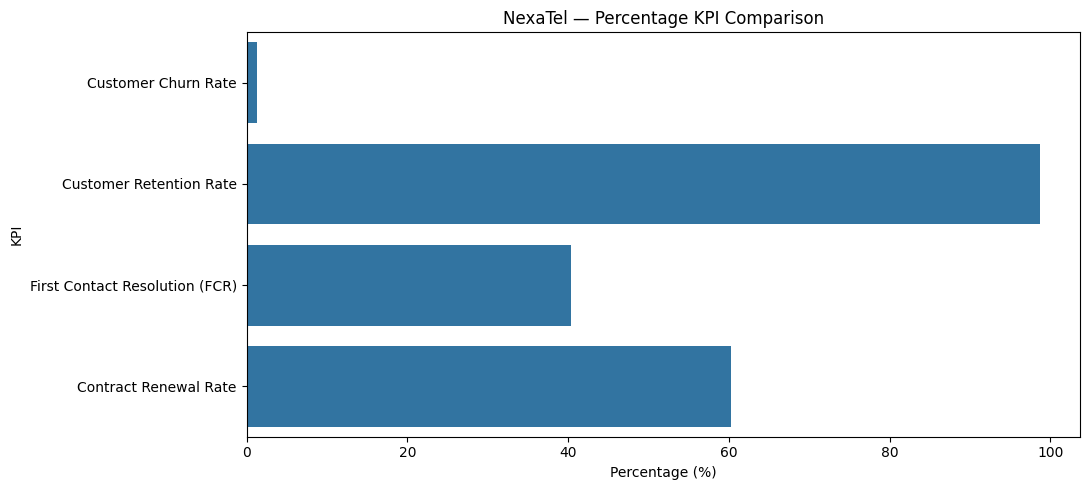

Chart saved at: D:\internmo internship projects\project 2\phase3_outputs\Phase3_Percentage_KPIs.png


In [19]:
percentage_kpis = kpi_table[
    kpi_table["Unit"] == "%"
].copy()

percentage_kpis["Value"] = pd.to_numeric(
    percentage_kpis["Value"], errors="coerce"
)

percentage_kpis = percentage_kpis.dropna(subset=["Value"])

if not percentage_kpis.empty:
    plt.figure(figsize=(11, 5))

    sns.barplot(
        data=percentage_kpis,
        x="Value",
        y="KPI"
    )

    plt.title("NexaTel — Percentage KPI Comparison")
    plt.xlabel("Percentage (%)")
    plt.ylabel("KPI")
    plt.tight_layout()

    chart_path = OUTPUT_DIR / "Phase3_Percentage_KPIs.png"
    plt.savefig(chart_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Chart saved at:", chart_path.resolve())
else:
    print("Plot karne ke liye valid percentage KPIs available nahi hain.")

In [20]:
report_path = OUTPUT_DIR / "Phase3_KPI_Summary.txt"

with open(report_path, "w", encoding="utf-8") as file:
    file.write("NexaTel Customer Churn Analytics — Phase 3 KPI Summary\n")
    file.write("=" * 60 + "\n\n")
    file.write("Prepared by: Harsh Suman\n\n")

    for _, row in kpi_table.iterrows():
        value = row["Value"]

        if pd.isna(value):
            formatted_value = "Not available — check required columns/data"
        elif row["Unit"] == "%":
            formatted_value = f"{value:.2f}%"
        elif row["Unit"] == "INR":
            formatted_value = f"₹{value:,.2f}"
        elif row["Unit"] == "INR/month":
            formatted_value = f"₹{value:,.2f} per month"
        elif row["Unit"] == "INR per subscriber/month":
            formatted_value = f"₹{value:,.2f} per subscriber/month"
        elif row["Unit"] == "hours":
            formatted_value = f"{value:.2f} hours"
        elif row["Unit"] == "months":
            formatted_value = f"{value:.2f} months"
        else:
            formatted_value = str(value)

        file.write(f"KPI: {row['KPI']}\n")
        file.write(f"Value: {formatted_value}\n")
        file.write(f"Notes: {row['Notes']}\n")
        file.write("-" * 60 + "\n")

print("Report saved at:", report_path.resolve())

Report saved at: D:\internmo internship projects\project 2\phase3_outputs\Phase3_KPI_Summary.txt


In [21]:
print("KPI count:", len(kpi_table))
print("\nKPI completion check:")
display(
    kpi_table[["KPI", "Value", "Unit"]]
)

print("\nOutput files:")
for filepath in sorted(OUTPUT_DIR.iterdir()):
    print(filepath.name)

KPI count: 10

KPI completion check:


,KPI,Value,Unit
0,Customer Churn Rate,1.243604e+00,%
1,Customer Retention Rate,9.874344e+01,%
2,Monthly Recurring Revenue (MRR),1.492032e+07,INR
3,ARPU,9.519155e+02,INR per subscriber/month
4,Customer Lifetime Value (CLV),2.296347e+04,INR
5,Revenue Lost to Churn,2.566181e+06,INR/month
6,First Contact Resolution (FCR),4.041283e+01,%
7,Average Resolution Time,1.604447e+01,hours
8,Contract Renewal Rate,6.032163e+01,%
9,Average Customer Tenure,8.709531e+01,months



Output files:
Phase3_KPI_Results.csv
Phase3_KPI_Summary.txt
Phase3_Percentage_KPIs.png
